# Разведочный анализ данных (EDA): MovieLens

Цель: изучить структуру и качество данных для рекомендательной системы фильмов, выбрать даты временного разбиения и сформулировать требования к качеству данных.

Датасет и параметры берутся из `configs/params.yaml`. Все графики сохраняются в `reports/figures/` для вставки в отчёт.

## 0. Настройка

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import yaml

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
params = yaml.safe_load((ROOT / "configs" / "params.yaml").read_text(encoding="utf-8"))

DATASET = params["dataset"]
THRESHOLD = params["relevance_threshold"]
SEED = params["seed"]
np.random.seed(SEED)

DATA_DIR = ROOT / "data" / "raw" / DATASET
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.max_columns", 50)

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")

print("Датасет:", DATASET)
print("Папка с данными:", DATA_DIR)

Matplotlib is building the font cache; this may take a moment.


Датасет: ml-latest-small
Папка с данными: C:\kursovaya\movielens-recsys\data\raw\ml-latest-small


## 1. Загрузка данных

In [ ]:
ratings = pd.read_csv(DATA_DIR / "ratings.csv")
movies = pd.read_csv(DATA_DIR / "movies.csv")
tags = pd.read_csv(DATA_DIR / "tags.csv")
links = pd.read_csv(DATA_DIR / "links.csv")

for name, df in [("ratings", ratings), ("movies", movies), ("tags", tags), ("links", links)]:
    mem = df.memory_usage(deep=True).sum() / 1024**2
    print(f"{name:8s} строк: {len(df):>10,}  столбцов: {df.shape[1]}  память: {mem:.1f} МБ")

ratings  строк:    100,836  столбцов: 4  память: 3.1 МБ
movies   строк:      9,742  столбцов: 3  память: 0.6 МБ
tags     строк:      3,683  столбцов: 4  память: 0.1 МБ
links    строк:      9,742  столбцов: 3  память: 0.2 МБ


In [ ]:
display(ratings.head())
display(movies.head())
ratings.dtypes

,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


userId         int64
movieId        int64
rating       float64
timestamp      int64
dtype: object

Время оценки хранится в секундах от 1970 года (Unix time). Переведём его в дату.

In [ ]:
ratings["datetime"] = pd.to_datetime(ratings["timestamp"], unit="s")
tags["datetime"] = pd.to_datetime(tags["timestamp"], unit="s")
print("Первая оценка:", ratings["datetime"].min())
print("Последняя оценка:", ratings["datetime"].max())

Первая оценка: 1996-03-29 18:36:55
Последняя оценка: 2018-09-24 14:27:30


## 2. Проверка качества данных

In [ ]:
checks = {}

# пропуски
checks["Пропуски в ratings"] = int(ratings.isna().sum().sum())
checks["Пропуски в movies"] = int(movies.isna().sum().sum())
checks["Пропуски в links (tmdbId и др.)"] = int(links.isna().sum().sum())

# дубликаты
checks["Полные дубликаты строк ratings"] = int(ratings.duplicated().sum())
checks["Повторные оценки пары user-movie"] = int(ratings.duplicated(["userId", "movieId"]).sum())
checks["Дубликаты movieId в movies"] = int(movies["movieId"].duplicated().sum())

# диапазон и шаг оценок
checks["Оценки вне диапазона 0.5-5"] = int((~ratings["rating"].between(0.5, 5)).sum())
checks["Оценки не кратные 0.5"] = int(((ratings["rating"] * 2) % 1 != 0).sum())

# ссылочная целостность
checks["Оценки фильмов, которых нет в movies"] = int((~ratings["movieId"].isin(movies["movieId"])).sum())
checks["Фильмы без единой оценки"] = int((~movies["movieId"].isin(ratings["movieId"])).sum())

# метаданные фильмов
checks["Фильмы без жанров"] = int((movies["genres"] == "(no genres listed)").sum())
movies["year"] = pd.to_numeric(movies["title"].str.extract(r"\((\d{4})\)\s*$")[0], errors="coerce")
checks["Фильмы без года в названии"] = int(movies["year"].isna().sum())
checks["Повторяющиеся названия фильмов"] = int(movies["title"].duplicated().sum())

# время
checks["Оценки с датой в будущем"] = int((ratings["datetime"] > pd.Timestamp.now()).sum())

quality = pd.DataFrame({"Проверка": checks.keys(), "Найдено": checks.values()})
quality["Статус"] = np.where(quality["Найдено"] == 0, "OK", "Внимание")
quality

,Проверка,Найдено,Статус
0,Пропуски в ratings,0,OK
1,Пропуски в movies,0,OK
2,Пропуски в links (tmdbId и др.),8,Внимание
3,Полные дубликаты строк ratings,0,OK
4,Повторные оценки пары user-movie,0,OK
5,Дубликаты movieId в movies,0,OK
6,Оценки вне диапазона 0.5-5,0,OK
7,Оценки не кратные 0.5,0,OK
8,"Оценки фильмов, которых нет в movies",0,OK
9,Фильмы без единой оценки,18,Внимание


Строки со статусом «Внимание» не обязательно ошибки. Например, фильмы без оценок или без жанров — нормальная ситуация для каталога, но их нужно учесть при обучении и в резервной стратегии. Посмотрим на найденные случаи подробнее.

In [ ]:
dup_titles = movies[movies["title"].duplicated(keep=False)].sort_values("title")
display(dup_titles.head(10))
display(movies[movies["year"].isna()].head(10))

,movieId,title,genres,year
4169,6003,Confessions of a Dangerous Mind (2002),Comedy|Crime|Drama|Thriller,2002.0
9106,144606,Confessions of a Dangerous Mind (2002),Comedy|Crime|Drama|Romance|Thriller,2002.0
650,838,Emma (1996),Comedy|Drama|Romance,1996.0
5601,26958,Emma (1996),Romance,1996.0
5854,32600,Eros (2004),Drama,2004.0
9135,147002,Eros (2004),Drama|Romance,2004.0
2141,2851,Saturn 3 (1980),Adventure|Sci-Fi|Thriller,1980.0
9468,168358,Saturn 3 (1980),Sci-Fi|Thriller,1980.0
5931,34048,War of the Worlds (2005),Action|Adventure|Sci-Fi|Thriller,2005.0
6932,64997,War of the Worlds (2005),Action|Sci-Fi,2005.0


,movieId,title,genres,year
6059,40697,Babylon 5,Sci-Fi,NaN
9031,140956,Ready Player One,Action|Sci-Fi|Thriller,NaN
9091,143410,Hyena Road,(no genres listed),NaN
9138,147250,The Adventures of Sherlock Holmes and Doctor W...,(no genres listed),NaN
9179,149334,Nocturnal Animals,Drama|Thriller,NaN
9259,156605,Paterson,(no genres listed),NaN
9367,162414,Moonlight,Drama,NaN
9448,167570,The OA,(no genres listed),NaN
9514,171495,Cosmos,(no genres listed),NaN
9515,171631,Maria Bamford: Old Baby,(no genres listed),NaN


## 3. Общие характеристики и разреженность

In [ ]:
n_users = ratings["userId"].nunique()
n_movies = ratings["movieId"].nunique()
n_ratings = len(ratings)
density = n_ratings / (n_users * n_movies)

summary = pd.Series({
    "Пользователей": n_users,
    "Фильмов с оценками": n_movies,
    "Фильмов в каталоге": movies["movieId"].nunique(),
    "Оценок": n_ratings,
    "Заполненность матрицы, %": round(density * 100, 3),
    "Разреженность, %": round((1 - density) * 100, 3),
    "Оценок на пользователя (медиана)": ratings.groupby("userId").size().median(),
    "Оценок на фильм (медиана)": ratings.groupby("movieId").size().median(),
})
summary.to_frame("Значение")

,Значение
Пользователей,610.0
Фильмов с оценками,9724.0
Фильмов в каталоге,9742.0
Оценок,100836.0
"Заполненность матрицы, %",1.7
"Разреженность, %",98.3
Оценок на пользователя (медиана),70.5
Оценок на фильм (медиана),3.0


## 4. Распределение оценок

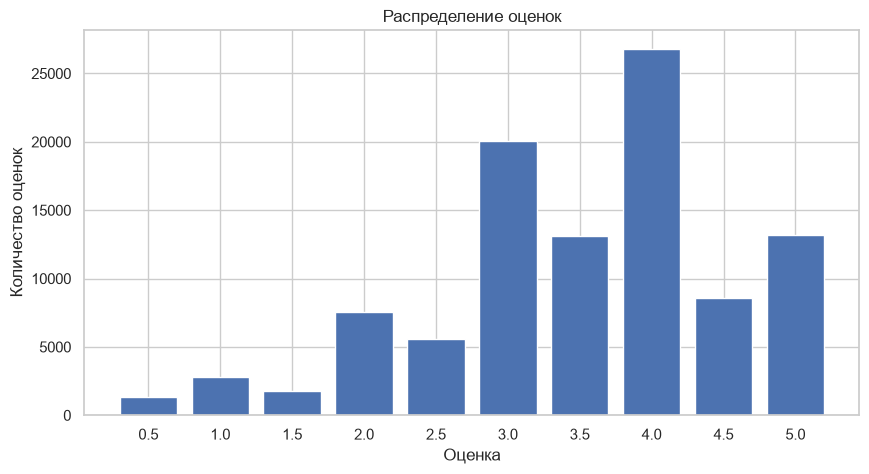

Средняя оценка: 3.50
Доля «релевантных» оценок (>= 4.0): 48.2%
Доля целых оценок: 69.9%


In [ ]:
fig, ax = plt.subplots()
counts = ratings["rating"].value_counts().sort_index()
ax.bar(counts.index.astype(str), counts.values, color="#4C72B0")
ax.set_xlabel("Оценка")
ax.set_ylabel("Количество оценок")
ax.set_title("Распределение оценок")
save(fig, "01_rating_distribution")
plt.show()

share_rel = (ratings["rating"] >= THRESHOLD).mean()
print(f"Средняя оценка: {ratings['rating'].mean():.2f}")
print(f"Доля «релевантных» оценок (>= {THRESHOLD}): {share_rel:.1%}")
print(f"Доля целых оценок: {(ratings['rating'] % 1 == 0).mean():.1%}")

## 5. Активность пользователей и популярность фильмов

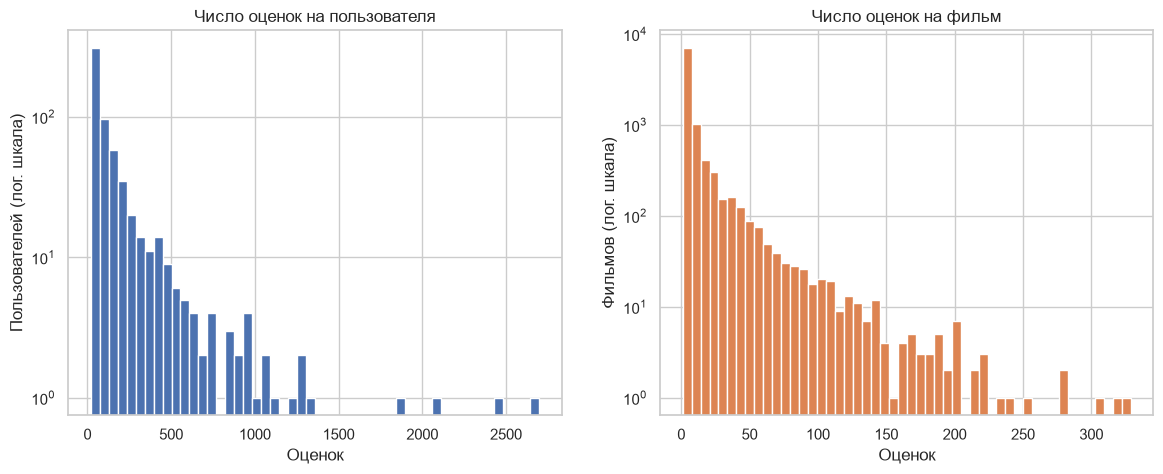

,На пользователя,На фильм
count,610.0,9724.0
mean,165.3,10.4
std,269.5,22.4
min,20.0,1.0
25%,35.0,1.0
50%,70.5,3.0
75%,168.0,9.0
max,2698.0,329.0


In [ ]:
user_cnt = ratings.groupby("userId").size()
movie_cnt = ratings.groupby("movieId").size()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(user_cnt, bins=50, color="#4C72B0", log=True)
axes[0].set_title("Число оценок на пользователя")
axes[0].set_xlabel("Оценок")
axes[0].set_ylabel("Пользователей (лог. шкала)")
axes[1].hist(movie_cnt, bins=50, color="#DD8452", log=True)
axes[1].set_title("Число оценок на фильм")
axes[1].set_xlabel("Оценок")
axes[1].set_ylabel("Фильмов (лог. шкала)")
save(fig, "02_activity_popularity")
plt.show()

pd.DataFrame({"На пользователя": user_cnt.describe(), "На фильм": movie_cnt.describe()}).round(1)

### «Длинный хвост»: какую долю оценок собирают самые популярные фильмы

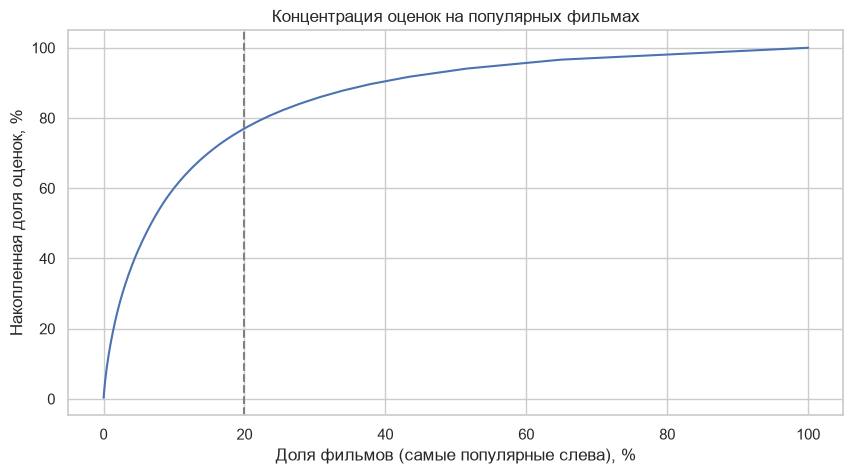

20% самых популярных фильмов собирают 77.0% всех оценок
Фильмов с < 2 оценками: 35.4%
Фильмов с < 6 оценками: 66.4%
Фильмов с < 11 оценками: 78.2%
Пользователей с < 20 оценками: 0.0%


In [ ]:
sorted_cnt = movie_cnt.sort_values(ascending=False).to_numpy()
cum_share = sorted_cnt.cumsum() / sorted_cnt.sum()
movie_share = np.arange(1, len(sorted_cnt) + 1) / len(sorted_cnt)

fig, ax = plt.subplots()
ax.plot(movie_share * 100, cum_share * 100, color="#4C72B0")
ax.axvline(20, ls="--", color="grey")
ax.set_xlabel("Доля фильмов (самые популярные слева), %")
ax.set_ylabel("Накопленная доля оценок, %")
ax.set_title("Концентрация оценок на популярных фильмах")
save(fig, "03_long_tail")
plt.show()

top20 = cum_share[int(len(sorted_cnt) * 0.2) - 1]
print(f"20% самых популярных фильмов собирают {top20:.1%} всех оценок")
for k in [1, 5, 10]:
    print(f"Фильмов с < {k + 1} оценками: {(movie_cnt <= k).mean():.1%}")
print(f"Пользователей с < 20 оценками: {(user_cnt < 20).mean():.1%}")

## 6. Динамика во времени и выбор дат разбиения

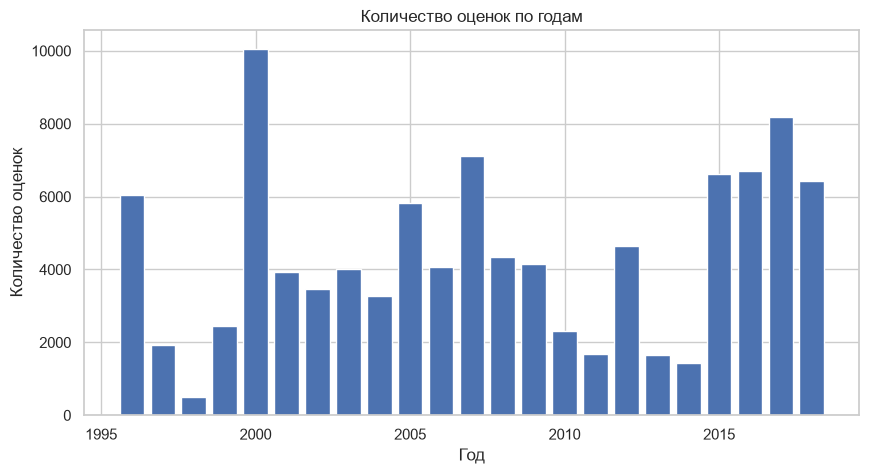

,оценок,пользователей,средняя_оценка
datetime,,,
1996,6040,97,3.54
1997,1916,33,3.73
1998,507,11,3.44
1999,2439,27,3.77
2000,10061,56,3.39
2001,3922,38,3.51
2002,3478,25,3.61
2003,4014,31,3.50
2004,3279,24,3.51


In [ ]:
by_year = ratings.groupby(ratings["datetime"].dt.year).agg(
    оценок=("rating", "size"),
    пользователей=("userId", "nunique"),
    средняя_оценка=("rating", "mean"),
)

fig, ax = plt.subplots()
ax.bar(by_year.index, by_year["оценок"], color="#4C72B0")
ax.set_xlabel("Год")
ax.set_ylabel("Количество оценок")
ax.set_title("Количество оценок по годам")
save(fig, "04_ratings_by_year")
plt.show()

by_year.round(2)

Даты разбиения выбираем по квантилям времени: первые 80% оценок — обучение, следующие 10% — валидация, последние 10% — тест. Затем проверяем, сколько пользователей и фильмов в валидации и тесте модель ни разу не видела при обучении (холодный старт).

In [ ]:
val_date = ratings["datetime"].quantile(0.8)
test_date = ratings["datetime"].quantile(0.9)

train = ratings[ratings["datetime"] < val_date]
val = ratings[(ratings["datetime"] >= val_date) & (ratings["datetime"] < test_date)]
test = ratings[ratings["datetime"] >= test_date]

def cold_share(part, known):
    users = part["userId"].isin(known["userId"])
    items = part["movieId"].isin(known["movieId"])
    return pd.Series({
        "оценок": len(part),
        "пользователей": part["userId"].nunique(),
        "новых пользователей, %": round((~part.drop_duplicates("userId")["userId"].isin(known["userId"])).mean() * 100, 1),
        "оценок от новых пользователей, %": round((~users).mean() * 100, 1),
        "оценок новых фильмов, %": round((~items).mean() * 100, 1),
    })

split_info = pd.DataFrame({
    "train": pd.Series({"оценок": len(train), "пользователей": train["userId"].nunique()}),
    "validation": cold_share(val, train),
    "test": cold_share(test, pd.concat([train, val])),
})
print("val_date: ", val_date.date())
print("test_date:", test_date.date())
split_info

val_date:  2016-03-22
test_date: 2017-06-21


,train,validation,test
"новых пользователей, %",NaN,66.1,63.5
оценок,80668.0,10084.0,10084.0
"оценок новых фильмов, %",NaN,10.1,14.8
"оценок от новых пользователей, %",NaN,90.2,83.5
пользователей,522.0,62.0,74.0


Найденные даты нужно записать в `configs/params.yaml` (поля `split.val_date` и `split.test_date`). Если доля оценок от новых пользователей в тесте очень велика, это важный вывод: значительная часть теста — холодный старт, и резервная стратегия будет работать часто.

## 7. Жанры

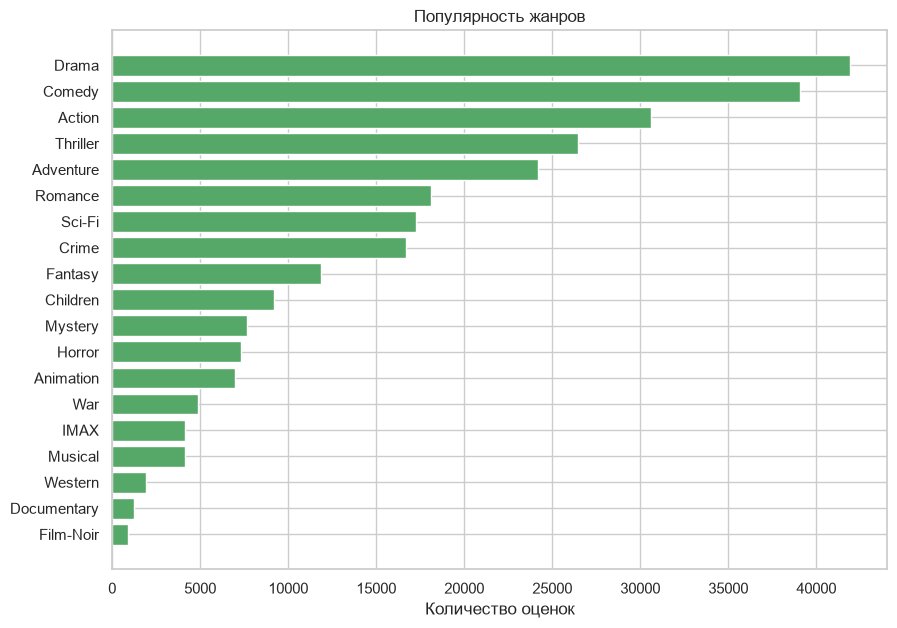

Жанров на фильм в среднем: 2.27


,оценок,средняя_оценка,фильмов
genre,,,
Drama,41928,3.66,4361
Comedy,39053,3.38,3756
Action,30635,3.45,1828
Thriller,26452,3.49,1894
Adventure,24161,3.51,1263
Romance,18124,3.51,1596
Sci-Fi,17243,3.46,980
Crime,16681,3.66,1199
Fantasy,11834,3.49,779


In [ ]:
genres = movies.assign(genre=movies["genres"].str.split("|")).explode("genre")
genres = genres[genres["genre"] != "(no genres listed)"]

genre_stats = (
    ratings.merge(genres[["movieId", "genre"]], on="movieId")
    .groupby("genre")
    .agg(оценок=("rating", "size"), средняя_оценка=("rating", "mean"))
    .join(genres.groupby("genre").size().rename("фильмов"))
    .sort_values("оценок", ascending=False)
)

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(genre_stats.index[::-1], genre_stats["оценок"][::-1], color="#55A868")
ax.set_xlabel("Количество оценок")
ax.set_title("Популярность жанров")
save(fig, "05_genres")
plt.show()

print("Жанров на фильм в среднем:", round(movies["genres"].str.count(r"\|").add(1).mean(), 2))
genre_stats.round(2)

## 8. Теги

In [ ]:
print("Всего тегов:", len(tags))
print("Уникальных тегов:", tags["tag"].nunique())
print("Пользователей, ставивших теги:", tags["userId"].nunique(), "из", n_users)
tags["tag"].str.lower().value_counts().head(15)

Всего тегов: 3683
Уникальных тегов: 1589
Пользователей, ставивших теги: 58 из 610


tag
in netflix queue      131
atmospheric            41
funny                  24
superhero              24
surreal                24
thought-provoking      24
sci-fi                 23
disney                 23
quirky                 22
religion               22
dark comedy            21
suspense               21
psychology             21
twist ending           20
visually appealing     20
Name: count, dtype: int64

## 9. Итоговая сводка

In [ ]:
final = pd.Series({
    "Датасет": DATASET,
    "Пользователей": n_users,
    "Фильмов с оценками": n_movies,
    "Оценок": n_ratings,
    "Разреженность, %": round((1 - density) * 100, 2),
    "Средняя оценка": round(ratings["rating"].mean(), 2),
    f"Доля оценок >= {THRESHOLD}, %": round(share_rel * 100, 1),
    "Доля оценок у топ-20% фильмов, %": round(top20 * 100, 1),
    "Период": f"{ratings['datetime'].min().date()} — {ratings['datetime'].max().date()}",
    "val_date": str(val_date.date()),
    "test_date": str(test_date.date()),
})
final.to_frame("Значение")

,Значение
Датасет,ml-latest-small
Пользователей,610
Фильмов с оценками,9724
Оценок,100836
"Разреженность, %",98.3
Средняя оценка,3.5
"Доля оценок >= 4.0, %",48.2
"Доля оценок у топ-20% фильмов, %",77.0
Период,1996-03-29 — 2018-09-24
val_date,2016-03-22


## 10. Выводы и требования к качеству данных

Отладочный прогон на ml-latest-small; итоговые выводы — в 01_eda_ml25m.ipynb